Name: Emily Savoie

Labpartner(s): Maru Shapiro

In [67]:
#import statements go here
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [66]:
import matplotlib as mpl
mpl.rcParams['font.size'] = 14

# Class 7.2

Today your assignment is the rest of the pandas unit and to catch up and think about your project topic, which is due by Sunday 10/13.

**W.1** Implement a function that takes as input three variables, and returns the largest of the three. Do this without using the Python max() function.

The goal of this exercise is to think about some internals that Python normally takes care of for us. All you need is some variables and if statements.

In [4]:
def max(var1, var2, var3):
    if var1 > var2 and var3:
        print (var1)
    elif var2 > var1 and var3:
        print (var2)
    else:
        print (var3)

In [5]:
max(3,6,1)

6


In [11]:
# verison with flexible argument number
def max(*args):
    max = args[0]
    for num in args:
        if num > max:
            max = num
    print(max)

In [12]:
max(3,9,8,10,23,1)

23


# Lecture 7.2

### Agenda:

- Questions
- Tropical Tidbits
- Movie project!

### Questions

For our project this week, I am unleashing you use LLMs for coding, and specifically how to make a series of images into a playable movie. For example, say you have a series of daily HYCOM SST plots, and you want to animate this, how would you do it? We'll strategize more in class about how to accomplish this as a team and with the help of ChatGPT, Claude, or whatever, and hopefully come up with a few different workflows you can share. 

# Lab 7.2

**E.0** Complete the previous labs if you are behind.

**E.1** Complete Data Manipulation with Pandas Ch 3-4 in datacamp.

**E.2** Make notes for yourself on progamming tecniques and commands you learned in the datacamp chapter above, including examples, comments and explainitory text. You can do this here or in a separate notebook that you link to here. Basically, you are making a cheat sheet for yourself.

[Reference Notebook](Reference_notebook.ipynb)

**E.3** For this week's project, find a series of images you want to animate. This can be model output, a series of other plots, whatever you want. Everyone needs to pick their own dataset. Work together and share ideas for different ways to make these movies, and work with an LLM to help you figure this out. Next week on Monday or Wednesday you will present your movie and tell us how you made it.

Animation of sea surface height for the 24 hours of the day that Hurricane Ida made landfall. 

In [3]:
# Import statements
import xarray as xr
import cartopy.crs as ccrs   
import cartopy.feature as cfeature 
from matplotlib.animation import FuncAnimation
from matplotlib.animation import FFMpegWriter

In [4]:
import warnings
warnings.filterwarnings('ignore')

In [ ]:
# Initial attempt: plot SSH on 8/29/2021
# Impport 24 hour data file from HYCOM
file_path= "2021_2d.nc4"

hycom_data = xr.open_dataarray(file_path, decode_times=True)
hycom_data

<xarray.DataArray 'ssh' (MT: 25, Latitude: 1537, Longitude: 2101)> Size: 323MB
[80730925 values with dtype=float32]
Coordinates:
  * MT         (MT) datetime64[ns] 200B 2021-08-29 ... 2021-08-30
  * Latitude   (Latitude) float32 6kB 18.09 18.1 18.11 ... 31.94 31.95 31.96
  * Longitude  (Longitude) float32 8kB -98.0 -97.99 -97.98 ... -77.01 -77.0
Attributes:
    _CoordinateAxes:  Date MT Latitude Longitude
    long_name:         sea surf. height  [01.0H]
    standard_name:    sea_surface_elevation
    units:            m
    valid_range:      [-0.8527999  0.8627538]

In [80]:
lat_min = hycom_data.Latitude.min()
lat_max = hycom_data.Latitude.max()
lon_min = hycom_data.Longitude.min()
lon_max = hycom_data.Longitude.max()

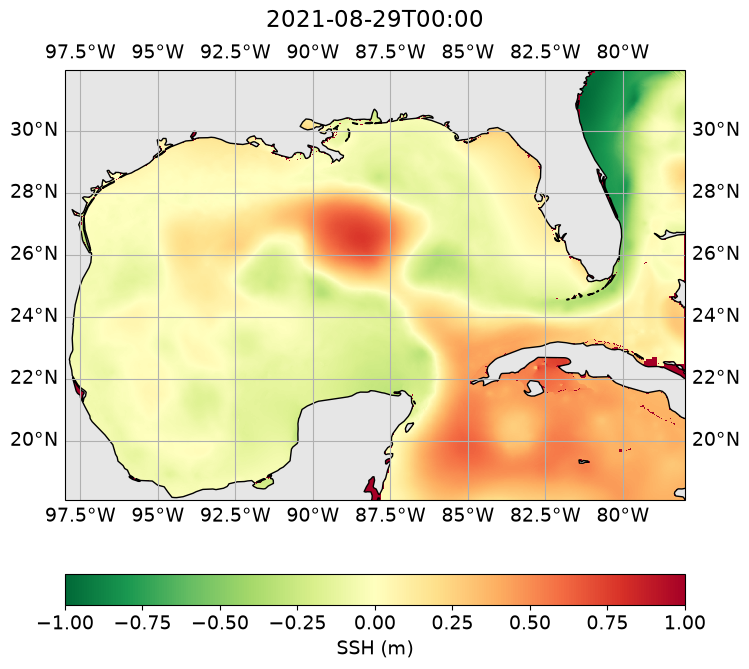

In [ ]:
fig,ax= plt.subplots(figsize =(8,8),subplot_kw=dict(projection=ccrs.PlateCarree()))
ax.set_extent( [lon_min, -78, lat_min, lat_max]) 

# Sets the land onto the projection with the right color and scale
land_50m = cfeature.NaturalEarthFeature('physical', 'land', '50m',
                                    edgecolor='black',
                                    facecolor='0.9')
ax.add_feature(land_50m)
ax.gridlines(draw_labels = True)

# let's fill in the following:
x = hycom_data.Longitude
y = hycom_data.Latitude
var = hycom_data.isel(MT=0)

mesh = ax.pcolormesh(x, y, hycom_data.isel(MT=0),
                     transform=ccrs.PlateCarree(), cmap="RdYlGn_r",
                    vmin = -1, vmax = 1)
plt.colorbar(mesh, ax=ax, orientation = 'horizontal', pad = 0.12, label = 'SSH (m)')

# Define a function to generate each time point frame
def update(i):
    mesh.set_array(hycom_data.isel(MT=i).values.ravel())
    ax.set_title(str(hycom_data.MT.values[i])[:16], pad = 12)
    return (mesh,)

# Connect frames together and save
anim = FuncAnimation(fig, update, frames=hycom_data.sizes["MT"], interval=250)
#anim.save("hycom_ssh_24h.gif", writer="pillow")
anim.save("hycom_ssh_24h.mp4", writer="ffmpeg", fps = 4, bitrate = 2000, dpi=150)
 

In [ ]:
# Attempt to plot surface current velocity and direction
#  Impport 24 hour data file from HYCOM
file_path= "2021_3z.nc4"

hycom_data = xr.open_dataset(file_path, decode_times=True)
hycom_data

<xarray.Dataset> Size: 39MB
Dimensions:    (MT: 24, Depth: 1, Latitude: 385, Longitude: 525)
Coordinates:
  * MT         (MT) datetime64[ns] 192B 2021-08-29 ... 2021-08-29T22:59:31.20...
  * Depth      (Depth) float32 4B 0.0
  * Latitude   (Latitude) float32 2kB 18.09 18.13 18.17 ... 31.89 31.93 31.96
  * Longitude  (Longitude) float32 2kB -98.0 -97.96 -97.92 ... -77.08 -77.04
Data variables:
    u          (MT, Depth, Latitude, Longitude) float32 19MB ...
    v          (MT, Depth, Latitude, Longitude) float32 19MB ...
Attributes:
    Conventions:         CF-1.0
    source:              HYCOM archive file
    experiment:          01.0
    history:             python
    title:               HYCOM
    History:             Translated to CF-1.0 Conventions by Netcdf-Java CDM ...
    geospatial_lat_min:  18.09164810180664
    geospatial_lat_max:  31.960647583007812
    geospatial_lon_min:  -98.0
    geospatial_lon_max:  -77.03997802734375

In [41]:
# .squeeze() will remove dimensions that are length 1
u = hycom_data['u'].squeeze()
u

<xarray.DataArray 'u' (MT: 24, Latitude: 385, Longitude: 525)> Size: 19MB
array([[[1.267651e+30, 1.267651e+30, ..., 1.267651e+30, 1.267651e+30],
        [1.267651e+30, 1.267651e+30, ..., 1.267651e+30, 1.267651e+30],
        ...,
        [1.267651e+30, 1.267651e+30, ..., 1.267651e+30, 1.267651e+30],
        [1.267651e+30, 1.267651e+30, ..., 1.267651e+30, 1.267651e+30]],

       [[1.267651e+30, 1.267651e+30, ..., 1.267651e+30, 1.267651e+30],
        [1.267651e+30, 1.267651e+30, ..., 1.267651e+30, 1.267651e+30],
        ...,
        [1.267651e+30, 1.267651e+30, ..., 1.267651e+30, 1.267651e+30],
        [1.267651e+30, 1.267651e+30, ..., 1.267651e+30, 1.267651e+30]],

       ...,

       [[1.267651e+30, 1.267651e+30, ..., 1.267651e+30, 1.267651e+30],
        [1.267651e+30, 1.267651e+30, ..., 1.267651e+30, 1.267651e+30],
        ...,
        [1.267651e+30, 1.267651e+30, ..., 1.267651e+30, 1.267651e+30],
        [1.267651e+30, 1.267651e+30, ..., 1.267651e+30, 1.267651e+30]],

       [[1.267651e+30, 1.267651e+30, ..., 1.267651e+30, 1.267651e+30],
        [1.267651e+30, 1.267651e+30, ..., 1.267651e+30, 1.267651e+30],
        ...,
        [1.267651e+30, 1.267651e+30, ..., 1.267651e+30, 1.267651e+30],
        [1.267651e+30, 1.267651e+30, ..., 1.267651e+30, 1.267651e+30]]],
      shape=(24, 385, 525), dtype=float32)
Coordinates:
  * MT         (MT) datetime64[ns] 192B 2021-08-29 ... 2021-08-29T22:59:31.20...
  * Latitude   (Latitude) float32 2kB 18.09 18.13 18.17 ... 31.89 31.93 31.96
  * Longitude  (Longitude) float32 2kB -98.0 -97.96 -97.92 ... -77.08 -77.04
    Depth      float32 4B 0.0
Attributes:
    _CoordinateAxes:  Date MT Depth Latitude Longitude
    long_name:        u-veloc. [01.0H]
    standard_name:    eastward_sea_water_velocity
    units:            m/s
    valid_range:      [-1.1239412  1.6126848]

In [42]:
v = hycom_data['v'].squeeze()
v

<xarray.DataArray 'v' (MT: 24, Latitude: 385, Longitude: 525)> Size: 19MB
array([[[1.267651e+30, 1.267651e+30, ..., 1.267651e+30, 1.267651e+30],
        [1.267651e+30, 1.267651e+30, ..., 1.267651e+30, 1.267651e+30],
        ...,
        [1.267651e+30, 1.267651e+30, ..., 1.267651e+30, 1.267651e+30],
        [1.267651e+30, 1.267651e+30, ..., 1.267651e+30, 1.267651e+30]],

       [[1.267651e+30, 1.267651e+30, ..., 1.267651e+30, 1.267651e+30],
        [1.267651e+30, 1.267651e+30, ..., 1.267651e+30, 1.267651e+30],
        ...,
        [1.267651e+30, 1.267651e+30, ..., 1.267651e+30, 1.267651e+30],
        [1.267651e+30, 1.267651e+30, ..., 1.267651e+30, 1.267651e+30]],

       ...,

       [[1.267651e+30, 1.267651e+30, ..., 1.267651e+30, 1.267651e+30],
        [1.267651e+30, 1.267651e+30, ..., 1.267651e+30, 1.267651e+30],
        ...,
        [1.267651e+30, 1.267651e+30, ..., 1.267651e+30, 1.267651e+30],
        [1.267651e+30, 1.267651e+30, ..., 1.267651e+30, 1.267651e+30]],

       [[1.267651e+30, 1.267651e+30, ..., 1.267651e+30, 1.267651e+30],
        [1.267651e+30, 1.267651e+30, ..., 1.267651e+30, 1.267651e+30],
        ...,
        [1.267651e+30, 1.267651e+30, ..., 1.267651e+30, 1.267651e+30],
        [1.267651e+30, 1.267651e+30, ..., 1.267651e+30, 1.267651e+30]]],
      shape=(24, 385, 525), dtype=float32)
Coordinates:
  * MT         (MT) datetime64[ns] 192B 2021-08-29 ... 2021-08-29T22:59:31.20...
  * Latitude   (Latitude) float32 2kB 18.09 18.13 18.17 ... 31.89 31.93 31.96
  * Longitude  (Longitude) float32 2kB -98.0 -97.96 -97.92 ... -77.08 -77.04
    Depth      float32 4B 0.0
Attributes:
    _CoordinateAxes:  Date MT Depth Latitude Longitude
    long_name:        v-veloc. [01.0H]
    standard_name:    northward_sea_water_velocity
    units:            m/s
    valid_range:      [-1.1561572  1.9027985]

In [ ]:
# Combine the north-south and east-west speeds into one
speed = np.hypot(u, v).squeeze()
speed

<xarray.DataArray 'u' (MT: 24, Latitude: 385, Longitude: 525)> Size: 19MB
array([[[1.7927286e+30, 1.7927286e+30, 1.7927286e+30, ...,
         1.7927286e+30, 1.7927286e+30, 1.7927286e+30],
        [1.7927286e+30, 1.7927286e+30, 1.7927286e+30, ...,
         1.7927286e+30, 1.7927286e+30, 1.7927286e+30],
        [1.7927286e+30, 1.7927286e+30, 1.7927286e+30, ...,
         1.7927286e+30, 1.7927286e+30, 1.7927286e+30],
        ...,
        [1.7927286e+30, 1.7927286e+30, 1.7927286e+30, ...,
         1.7927286e+30, 1.7927286e+30, 1.7927286e+30],
        [1.7927286e+30, 1.7927286e+30, 1.7927286e+30, ...,
         1.7927286e+30, 1.7927286e+30, 1.7927286e+30],
        [1.7927286e+30, 1.7927286e+30, 1.7927286e+30, ...,
         1.7927286e+30, 1.7927286e+30, 1.7927286e+30]],

       [[1.7927286e+30, 1.7927286e+30, 1.7927286e+30, ...,
         1.7927286e+30, 1.7927286e+30, 1.7927286e+30],
        [1.7927286e+30, 1.7927286e+30, 1.7927286e+30, ...,
         1.7927286e+30, 1.7927286e+30, 1.7927286e+30],
        [1.7927286e+30, 1.7927286e+30, 1.7927286e+30, ...,
         1.7927286e+30, 1.7927286e+30, 1.7927286e+30],
...
         1.7927286e+30, 1.7927286e+30, 1.7927286e+30],
        [1.7927286e+30, 1.7927286e+30, 1.7927286e+30, ...,
         1.7927286e+30, 1.7927286e+30, 1.7927286e+30],
        [1.7927286e+30, 1.7927286e+30, 1.7927286e+30, ...,
         1.7927286e+30, 1.7927286e+30, 1.7927286e+30]],

       [[1.7927286e+30, 1.7927286e+30, 1.7927286e+30, ...,
         1.7927286e+30, 1.7927286e+30, 1.7927286e+30],
        [1.7927286e+30, 1.7927286e+30, 1.7927286e+30, ...,
         1.7927286e+30, 1.7927286e+30, 1.7927286e+30],
        [1.7927286e+30, 1.7927286e+30, 1.7927286e+30, ...,
         1.7927286e+30, 1.7927286e+30, 1.7927286e+30],
        ...,
        [1.7927286e+30, 1.7927286e+30, 1.7927286e+30, ...,
         1.7927286e+30, 1.7927286e+30, 1.7927286e+30],
        [1.7927286e+30, 1.7927286e+30, 1.7927286e+30, ...,
         1.7927286e+30, 1.7927286e+30, 1.7927286e+30],
        [1.7927286e+30, 1.7927286e+30, 1.7927286e+30, ...,
         1.7927286e+30, 1.7927286e+30, 1.7927286e+30]]],
      shape=(24, 385, 525), dtype=float32)
Coordinates:
  * MT         (MT) datetime64[ns] 192B 2021-08-29 ... 2021-08-29T22:59:31.20...
  * Latitude   (Latitude) float32 2kB 18.09 18.13 18.17 ... 31.89 31.93 31.96
  * Longitude  (Longitude) float32 2kB -98.0 -97.96 -97.92 ... -77.08 -77.04
    Depth      float32 4B 0.0
Attributes:
    _CoordinateAxes:  Date MT Depth Latitude Longitude
    long_name:        u-veloc. [01.0H]
    standard_name:    eastward_sea_water_velocity
    units:            m/s
    valid_range:      [-1.1239412  1.6126848]

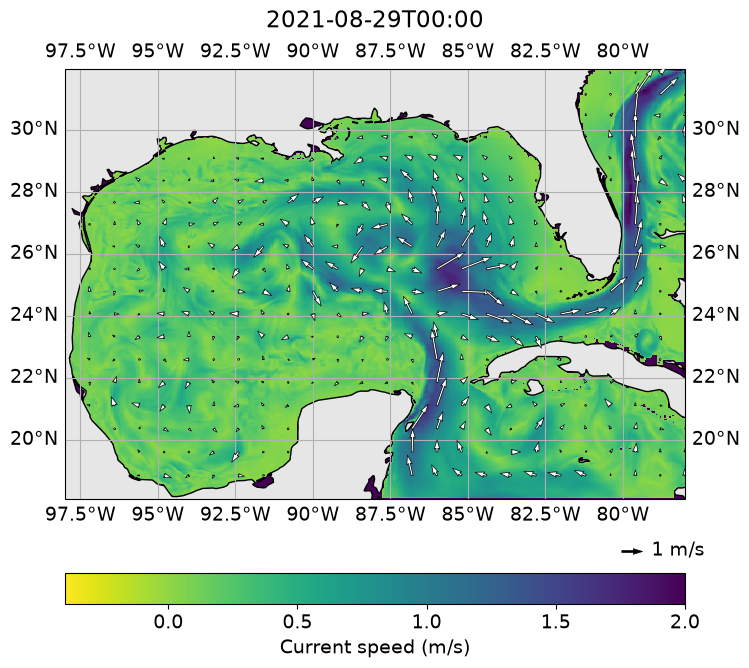

In [ ]:
fig,ax= plt.subplots(figsize =(8,8),
                     subplot_kw=dict(projection=ccrs.PlateCarree()))
ax.set_extent( [lon_min, -78, lat_min, lat_max]) 

# Sets the land onto the projection with the right color and scale
land_50m = cfeature.NaturalEarthFeature('physical', 'land', '50m',
                                    edgecolor='black',
                                    facecolor='0.9')
ax.add_feature(land_50m)
ax.gridlines(draw_labels = True)

mesh = ax.pcolormesh(speed.Longitude, speed.Latitude, speed.isel(MT=0),
                     transform=ccrs.PlateCarree(), cmap="viridis_r",
                     vmin=-0.4, vmax=2)
plt.colorbar(mesh, ax = ax, label="Current speed (m/s)", pad = 0.12, 
             orientation = 'horizontal')

step = 20
lon_q = u.Longitude.values[::step]
lat_q = u.Latitude.values[::step]

# Function defintion to calculate the directional speed for each defined point for each frame
# Removes points that are high; accounting for HYCOM fill value being 1e+30
def uv(i):
    U = u.isel(MT=i).values[::step, ::step]
    V = v.isel(MT=i).values[::step, ::step]
    # hard cap to remove fill value cells with fake numbers
    bad = ~((np.abs(U) < 10) & (np.abs(V) < 10))
    return np.where(bad, np.nan, U), np.where(bad, np.nan, V)

# Adds arrows to frames
quiv = ax.quiver(lon_q, lat_q, *uv(0), transform=ccrs.PlateCarree(),
                 facecolor="white", edgecolor ='black', linewidth = 0.5,
                 scale=30, width=0.003, zorder=4)
ax.quiverkey(quiv, 0.93, -0.12, 1, "1 m/s", labelpos="E", 
             color = 'black', coordinates="axes")

title = ax.set_title("", pad = 11)

# Function to create image for each time point 
def update(i):
    mesh.set_array(speed.isel(MT=i).values.ravel())
    quiv.set_UVC(*uv(i))
    title.set_text(np.datetime_as_string(speed.MT.values[i], unit="m"))
    return mesh, quiv, title

# Stitch together and save
anim = FuncAnimation(fig, update, frames=speed.sizes["MT"], interval=250)
anim.save("hycom_speed.mp4", 
          writer=FFMpegWriter(fps=4, extra_args=["-pix_fmt", "yuv420p"]), dpi=150)


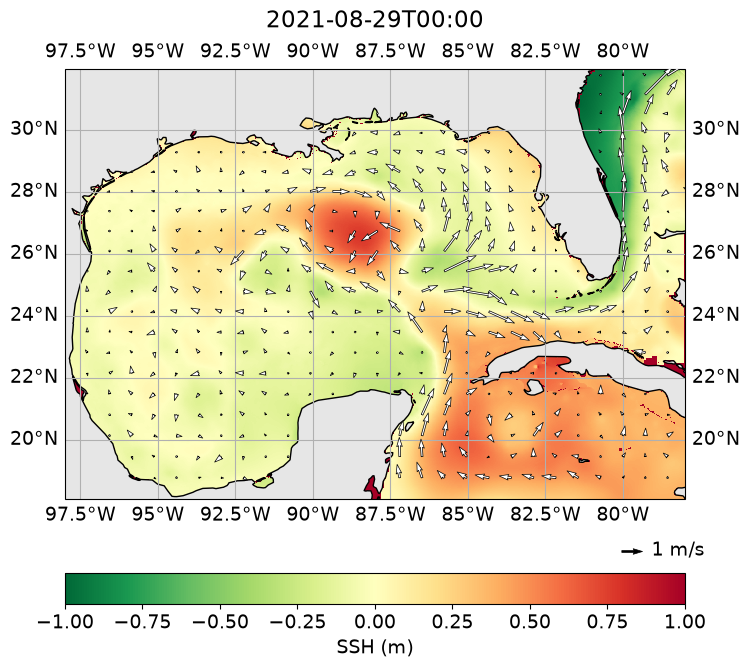

In [ ]:
# Decided to do SSH with the current arrows 

fig,ax= plt.subplots(figsize =(8,8),
                     subplot_kw=dict(projection=ccrs.PlateCarree()))
ax.set_extent( [lon_min, -78, lat_min, lat_max]) 

# Sets the land onto the projection with the right color and scale
land_50m = cfeature.NaturalEarthFeature('physical', 'land', '50m',
                                    edgecolor='black',
                                    facecolor='0.9')
ax.add_feature(land_50m)
ax.gridlines(draw_labels = True)

# let's fill in the following:
x = hycom_data.Longitude
y = hycom_data.Latitude

mesh = ax.pcolormesh(x, y, hycom_data.isel(MT=0),
                     transform=ccrs.PlateCarree(), cmap="RdYlGn_r",
                    vmin = -1, vmax = 1)
plt.colorbar(mesh, ax=ax, orientation = 'horizontal', pad = 0.12, label = 'SSH (m)')

step = 18
lon_q = u.Longitude.values[::step]
lat_q = u.Latitude.values[::step]

def uv(i):
    U = u.isel(MT=i).values[::step, ::step]
    V = v.isel(MT=i).values[::step, ::step]
    # hard cap to remove fill value cells with fake numbers
    bad = ~((np.abs(U) < 10) & (np.abs(V) < 10))
    return np.where(bad, np.nan, U), np.where(bad, np.nan, V)

quiv = ax.quiver(lon_q, lat_q, *uv(0), transform=ccrs.PlateCarree(),
                 facecolor="white", edgecolor ='black', linewidth = 0.5,
                 scale=30, width=0.003, zorder=4)
ax.quiverkey(quiv, 0.93, -0.12, 1, "1 m/s", labelpos="E", 
             color = 'black', coordinates="axes")

title = ax.set_title("", pad = 11)

def update(i):
    mesh.set_array(hycom_data.isel(MT=i).values.ravel())
    quiv.set_UVC(*uv(i))
    title.set_text(np.datetime_as_string(speed.MT.values[i], unit="m"))
    return mesh, quiv, title

anim = FuncAnimation(fig, update, frames=u.sizes["MT"], interval=250)
anim.save("hycom_ssh_speed.mp4", 
          writer=FFMpegWriter(fps=4, extra_args=["-pix_fmt", "yuv420p"]), dpi=150)
